# Writing data to and reading data from a Database using Python

**This Jupyter notebook does the following:**

- Creates a SQLite database and a SQL table for rental apartment data
- Reads the prepared apartment data from a CSV file and writes it into the SQL table
- Queries the SQL table using Python and SQL
- Plots a histogram of the rental prices
- Closes the database connection

## Libraries and settings

In [1]:
# Libraries
import os
import sqlite3
import fnmatch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

# Function to close a sqlite db-connection
def check_conn(conn):
     try:
        conn.cursor()
        return True
     except Exception as ex:
        return False

# Get current working directory
print(os.getcwd())

/workspaces/ARM-Stejsnat/Week_08


## Create sqlite data base

In [2]:
# Create data base
conn = sqlite3.connect('./Data/apartment_database.db') 

# Create cursor object to execute SQL commands
cursor = conn.cursor()

# Show dbs in the folder 'Data'
flist = fnmatch.filter(os.listdir('./Data'), '*.db')
for i in flist:
    print(i)

apartment_database.db


## Create SQL-table in the database

In [3]:
# Delete the table if it already exists (e.g. when the notebook is run several times)
cursor.execute('DROP TABLE IF EXISTS apartments_table')

# Create the SQL-table with the column names and data types defined below
cursor.execute('''CREATE TABLE apartments_table (OrderId VARCHAR(50),
                                                 Address VARCHAR(200),
                                                 Rooms DECIMAL(8,2),
                                                 Area INT(8),
                                                 Price DECIMAL(8,2))''')
# Confirm changes to the table
conn.commit()

## Read data from file to data frame

In [4]:
df = pd.read_csv('./Data/apartments_data_prepared.csv',
                  sep=',', 
                  encoding='utf-8')[['web-scraper-order', 'address_raw', 'rooms', 'area', 'price']]
print(df.shape)
df.head(5)

(1008, 5)


,web-scraper-order,address_raw,rooms,area,price
0,1693998201-1,"Neuhusstrasse 6, 8630 Rüti ZH, ZH",3.0,49.0,1441.0
1,1693998201-2,"Zürcherstrasse 1, 8173 Neerach, ZH",3.5,65.0,1850.0
2,1693998201-3,"Cramerstrasse 8-12, 8004 Zürich, ZH",NaN,NaN,2686.0
3,1693998201-4,"Cramerstrasse 8-12, 8004 Zürich, ZH",2.0,54.0,4853.0
4,1693998201-5,"Rotachstrasse 33, 8003 Zürich, ZH",2.0,49.0,4335.0


## Write data to the SQL-table in data base

In [5]:
# Rename the columns of the data frame according to the columns of the SQL-table
df_sql = df.rename(columns={'web-scraper-order': 'OrderId',
                            'address_raw': 'Address',
                            'rooms': 'Rooms',
                            'area': 'Area',
                            'price': 'Price'})

# Append the data to the (empty) SQL-table created above
df_sql.to_sql(name = 'apartments_table',
              con = conn,
              index = False,
              if_exists = 'append')

# Confirm changes to the table
conn.commit()

## Query the SQL-table

In [6]:
# Query the SQL-table
cursor.execute('''SELECT *
               FROM apartments_table
               WHERE rooms >=1''')

df = pd.DataFrame(cursor.fetchall(), 
                  columns=['OrderId','Address','Rooms','Area','Price'])    
df

,OrderId,Address,Rooms,Area,Price
0,1693998201-1,"Neuhusstrasse 6, 8630 Rüti ZH, ZH",3.0,49.0,1441.0
1,1693998201-2,"Zürcherstrasse 1, 8173 Neerach, ZH",3.5,65.0,1850.0
2,1693998201-4,"Cramerstrasse 8-12, 8004 Zürich, ZH",2.0,54.0,4853.0
3,1693998201-5,"Rotachstrasse 33, 8003 Zürich, ZH",2.0,49.0,4335.0
4,1693998201-16,"Wolframplatz 1, 8045 Zürich, ZH",2.0,32.0,3515.0
...,...,...,...,...,...
958,1693998381-1004,"Hölderlinstrasse 12, 8032 Zürich, ZH",3.5,82.0,2830.0
959,1693998381-1005,"Hegifeldstrasse 70, 8404 Reutlingen (Winterthu...",4.0,73.0,1713.0
960,1693998381-1006,"Holzmoosrütisteig 2b, 8820 Wädenswil, ZH",4.5,110.0,3500.0
961,1693998381-1007,"Vogelbuckstrasse 25, 8307 Effretikon, ZH",3.0,68.0,1650.0


## Plot histogramm of rental prices

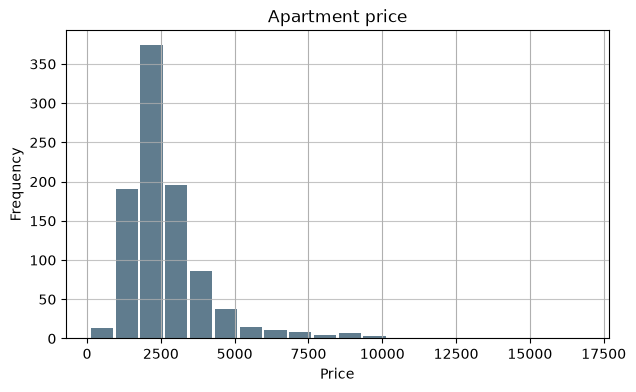

In [12]:
# Create a histogram
plt.figure(figsize=(7,4))
df.Price.plot.hist(grid=True, 
                   bins=20, 
                   rwidth=0.9,
                   color='#607c8e')
plt.title('Apartment price')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)

### Additional SQL-queries

In [13]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('./Data/apartment_database.db')

df_filtered = pd.read_sql_query("""
    SELECT *
    FROM apartments_table
    WHERE Rooms >= 4.0
      AND Area >= 100
""", conn)

conn.close()

print(f"Anzahl Apartments: {len(df_filtered)}")
display(df_filtered)

Anzahl Apartments: 239


,OrderId,Address,Rooms,Area,Price
0,1693998205-26,"Frowiesstrasse 36, 8344 Bäretswil, ZH",5.5,140,2750.0
1,1693998205-27,"Kanzleistrasse 15, 8418 Schlatt ZH, ZH",4.5,104,2700.0
2,1693998205-29,"Bolletweg 14, 8934 Knonau, ZH",5.5,150,3390.0
3,1693998205-31,"Adlergass 6, 8805 Richterswil, ZH",5.5,165,NaN
4,1693998205-33,"Haldenstrasse 67, 8602 Wangen b. Dübendorf, ZH",4.5,118,3390.0
...,...,...,...,...,...
234,1693998381-998,"Tösstalstrasse 12, 8492 Wila, ZH",4.5,109,1980.0
235,1693998381-999,"Murzlenstrasse 66, 8166 Niederweningen, ZH",4.5,111,2700.0
236,1693998381-1001,"Murzlenstrasse 66, 8166 Niederweningen, ZH",4.5,111,2800.0
237,1693998381-1006,"Holzmoosrütisteig 2b, 8820 Wädenswil, ZH",4.5,110,3500.0


### Write an SQL-query to calculate the average price per room size

In [14]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('./Data/apartment_database.db')

df_avg_price = pd.read_sql_query("""
    SELECT Rooms, AVG(Price) AS AveragePrice
    FROM apartments_table
    WHERE Rooms IS NOT NULL
    GROUP BY Rooms
    ORDER BY Rooms
""", conn)

conn.close()

display(df_avg_price.round(2))

,Rooms,AveragePrice
0,1.0,1290.31
1,1.5,2036.42
2,2.0,2133.38
3,2.5,2512.57
4,3.0,2112.02
5,3.5,2643.37
6,4.0,2890.26
7,4.5,3116.34
8,5.0,2993.33
9,5.5,3714.03


### Average area per room size

In [15]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('./Data/apartment_database.db')

df_avg_area = pd.read_sql_query("""
    SELECT Rooms, AVG(Area) AS AverageArea
    FROM apartments_table
    WHERE Rooms IS NOT NULL AND Area IS NOT NULL
    GROUP BY Rooms
    ORDER BY Rooms
""", conn)

conn.close()

display(df_avg_area.round(2))

,Rooms,AverageArea
0,1.0,32.09
1,1.5,35.53
2,2.0,54.43
3,2.5,67.32
4,3.0,68.98
5,3.5,89.86
6,4.0,96.13
7,4.5,114.78
8,5.0,110.00
9,5.5,154.54


## Close db connection (if open)

In [8]:
# Close db connection (if open)
try:
    if check_conn(conn):
        conn.close()
    else:
        pass
except:
    pass

# Status (True = open, False = closed)
print(check_conn(conn))

False


### Jupyter notebook --footer info-- (please always provide this at the end of each notebook)

In [9]:
import os
import platform
import socket
from platform import python_version
from datetime import datetime

print('-----------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print('Python Version:', python_version())
print('-----------------------------------')

-----------------------------------
POSIX
Linux | 6.8.0-1064-azure
Datetime: 2026-11-07 13:41:19
Python Version: 3.11.18
-----------------------------------
